# 提高程序的执行效率

Python 是动态语言，开发起来轻松。但执行速度往往偏慢，在计算密集的程序里，Python 与 C 之间能差上几十倍到几百倍。

所以通常的做法是调用 NumPy、SciPy 这类用 C 写成的扩展库，尽量不用 Python 的循环写数值计算；现有库不够用的部分，就只用快的语言写出计算的核心，再从 Python 调用。这样开发的速度与计算的速度可以兼顾。

不过用 C 写扩展库会失去 Python 的便利：要自己解析参数、管理引用计数、记住 Python/C API，注意力就离开原本的问题了。

这一章以 Julia 集合的计算为题材，比较用 CFFI、ctypes、Cython、Numba 提速的方法，各自详细的用法留到后面的章节。

In [1]:
import numpy as np
import numba as nb
import cmath
import random
import helper.matplotlib
from matplotlib import pyplot as plt

## Python 的计算为什么慢

原因有两个。

1. Python 的对象把 C 的数据包在里面。而被包住的数据地址并不连续。所以 CPU 缓存用不上；NumPy 的 `ndarray` 解决了这个问题。
2. Python 的程序跑在 Python 虚拟机上，即使是很小的计算也要调用好几个 Python/C API 函数；在循环里反复调用 Python 函数，调用的开销就会超过计算本身。而 NumPy 的 `ufunc` 把循环写进 C，正是为了解决这一点。

### Python 的对象

In [2]:
import sys  # 运行环境的信息

aint = 10000
sys.getsizeof(aint)

28

Python 里连整数都是作为对象放在内存中的。因为它还带着类型与引用计数的信息；下面的程序可以看出，Python 的一个整数占了 28 字节。而在 C 这类语言里，可以从 16 位、32 位、64 位整数中挑出需要的大小。

用 `sys.getrefcount()` 可以查对象的引用计数：下面的程序先显示 `aint` 的引用计数，再用列表 `alist` 引用它 10 次，最后用 `del` 删掉列表，从输出可以看出引用计数在变。

由此可知，Python 的列表只是持有对其他对象的引用，即使是整数列表，整数的数据本身也不在连续的内存里，这对 CPU 缓存很不利。

In [3]:
print(sys.getrefcount(aint))  # 来自变量的 1 个引用
alist = [aint] * 10            # 列表持有 10 个引用
print(sys.getrefcount(aint))  # 引用变多了
del alist
print(sys.getrefcount(aint))  # 回到原来的值

2
12
2


NumPy 的数组把数据放在一块连续的内存里。不过要把某个元素取出来在 Python 里计算，就得把这个元素重新包成 Python 对象：这个处理叫装箱(boxing)，反过来叫拆箱(unboxing)。

下面的例子里，从列表取出的元素就是对象本身，取两次也是同一个对象；而从数组取出的元素每次都要装箱，成为新的对象。用 `is` 可以判断两个引用是否指向同一个对象。引用与对象的关系如下图所示，Python 在计算之前要做引用的解析、装箱与拆箱，这就是它慢的原因之一。

![对象的引用与装箱](images/python-reference.svg)

In [4]:
import numpy as np

alist = [1000, 1001, 1002]  # 列表持有对对象的引用
arr = np.array(alist)
a = alist[1]
b = alist[1]
c = arr[1]
d = arr[1]
print(a is b)
print(c is d)

True
False


### 解释器

Python 的程序在 Python 虚拟机上运行：执行时先把源码编译成字节码，再由解释器执行这些字节码。而这个解释器是栈式机器，把状态放在栈上。

用 `dis` 模块可以显示函数的字节码，下面的程序给出 `hypot()` 的字节码：计算 `(a**2 + b**2) ** 0.5` 要执行从 `RESUME` 到 `RETURN_VALUE` 共 11 条字节码。

* `LOAD_FAST_BORROW` 把局部变量的值压到栈上(因为是借用，不增加引用计数)。
* `LOAD_SMALL_INT` 与 `LOAD_CONST` 把常量压到栈上。
* `BINARY_OP` 拿栈顶的两个值做运算并把结果压回去；从 3.11 起 `BINARY_ADD`、`BINARY_POWER` 这类指令合并成一条，用参数编号选运算种类，其中 `8` 是 `**`、`0` 是 `+`。
* `RETURN_VALUE` 返回栈顶的值。

In [5]:
import dis


def hypot(a, b):  # 两点之间的距离
    return (a**2 + b**2) ** 0.5


dis.dis(hypot)

  4           RESUME                   0

  5           LOAD_FAST_BORROW         0 (a)
              LOAD_SMALL_INT           2
              BINARY_OP                8 (**)
              LOAD_FAST_BORROW         1 (b)
              LOAD_SMALL_INT           2
              BINARY_OP                8 (**)
              BINARY_OP                0 (+)
              LOAD_CONST               1 (0.5)
              BINARY_OP                8 (**)
              RETURN_VALUE


执行字节码的 C 程序是 `ceval.c`：3.11 之前，每条字节码的处理都写成 `case TARGET(...)` 排在一起；从 3.12 起改为把处理写在 `Python/bytecodes.c` 里，再由构建器生成 `generated_cases.c.h`。源码可以从下面的链接读到。

:::{seealso}
https://github.com/python/cpython/blob/master/Python/ceval.c

执行 Python 字节码的 C 语言源码
:::

下面给出 3.10 里 `LOAD_FAST` 与 `BINARY_ADD` 的处理，可以看出一条字节码对应着 C 代码的一整段；到了 3.14，`BINARY_ADD` 已经并入 `BINARY_OP`，这段处理会生成在 `generated_cases.c.h` 里。

加法的代码先检查对象是不是字符串，是字符串就调用拼接函数 `unicode_concatenate()`，否则调用 `PyNumber_Add()`；而在 `PyNumber_Add()` 内部，为了算出两个浮点数之和也要走很多处理。

```c
case TARGET(LOAD_FAST): {
    PyObject *value = GETLOCAL(oparg);
    if (value == NULL) {
        format_exc_check_arg(tstate, PyExc_UnboundLocalError,
                             UNBOUNDLOCAL_ERROR_MSG,
                             PyTuple_GetItem(co->co_varnames, oparg));
        goto error;
    }
    Py_INCREF(value);
    PUSH(value);
    FAST_DISPATCH();
}
```

```c
case TARGET(BINARY_ADD): {
    PyObject *right = POP();
    PyObject *left = TOP();
    PyObject *sum;
    if (PyUnicode_CheckExact(left) &&
             PyUnicode_CheckExact(right)) {
        sum = unicode_concatenate(tstate, left, right, f, next_instr);
    }
    else {
        sum = PyNumber_Add(left, right);
        Py_DECREF(left);
    }
    Py_DECREF(right);
    SET_TOP(sum);
    if (sum == NULL)
        goto error;
    DISPATCH();
}
```

## 配置 C 编译器

要让计算变快，就得用编译器把它变成机器码，本书用到 cffi、Cython、Numba 这三个工具，先安装扩展库。

```
conda install cython numba cffi
```

用 `cffi` 或 `Cython` 做扩展模块时，要先确定用哪个 C 编译器：Python 用 `distutils` 编译。而 `distutils` 按优先级从高到低读下面三个配置文件。

1. `distutils` 模块路径下的 `distutils.cfg`
2. 主目录下的 `pydistutils.cfg`
3. 当前目录下的 `setup.cfg`

下面的程序显示出这三个文件的路径，并用 `parse_config_files()` 读入设置；`build` 命令的 `compiler` 之所以是 `mingw32`，就是读到了 `setup.cfg` 里的设置，文件内容如下。

```
[build]
compiler=mingw32
```

:::{seealso}
https://github.com/niXman/mingw-builds-binaries

装好 MinGW-W64 之后，请把 `gcc.exe` 所在的文件夹加到 PATH 里；本书的环境(pixi)里，MinGW 的 `gcc` 已经在 PATH 上了。
:::

In [6]:
from distutils.core import Distribution

dist = Distribution()
print(dist.find_config_files())
dist.parse_config_files()
dist.command_options

['setup.cfg']


{'build': {'compiler': ('setup.cfg', 'mingw32')},
 'build_ext': {'compiler': ('setup.cfg', 'mingw32')}}

## 把 Julia 集合的计算变快

Julia 集合是复平面上构成分形的一片点集，由下面的式子反复迭代得到。

$$ f_{c}(z)=z^{2}+c$$

固定复数 $c$、从复数 $z_0$ 出发，就得到下面这个序列。

$$ z_{0},f_{c}(z_{0}),f_{c}(f_{c}(z_{0})),f_{c}(f_{c}(f_{c}(z_{0}))),\ldots .$$

这个序列要么发散到无穷，要么留在某个范围内；不发散的 $z_0$ 组成的集合就是 Julia 集合。

集合上的点可以用随机的逆迭代算出来。其中 $z_n$ 与 $c$ 都是复数，步骤如下。

1. 用 $z_{0} ={\frac  {1+{\sqrt  {1-4c}}}{2}}$ 初始化。
2. 计算 $z_{n} = \sqrt{z_{n-1} - c}$。
3. 以一半的概率把 $z_{n}$ 的符号取反。
4. 保存 $z_{n}$，回到第 2 步。

这个迭代写不成 NumPy 的 `ufunc`，只能用循环一次次算，下面的 `py_julia_set()` 就是这种实现。其中 `cmath` 是 Python 标准库中处理复数的模块。

In [7]:
import numpy as np
import cmath
import random


def py_julia_set(c, n):
    z = (1 + cmath.sqrt(1 - 4 * c)) / 2
    res = np.zeros(n, dtype=np.complex128)  # 存放结果的数组
    for i in range(n):
        z = cmath.sqrt(z - c)
        if random.randint(0, 1):
            z = -z
        res[i] = z
    return res


c = -0.512511498387847167 + 0.521295573094847167j
%timeit py_julia_set(c, 100000)
z = py_julia_set(c, 100000)

75.7 ms ± 14 ms per loop (mean ± std. dev. of 7 runs, 10 loops each)


`z` 是复数的数组，下面的代码取出实部与虚部，用 `histogram2d()` 做成二维直方图并画出来。

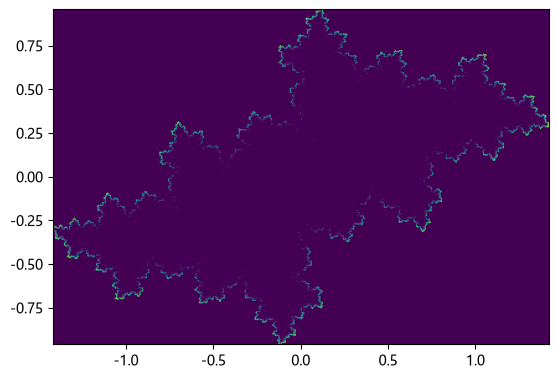

In [8]:
counts, xe, ye = np.histogram2d(z.real, z.imag, bins=400)  # 二维直方图
plt.imshow(np.log(counts.T + 1), extent=[xe[0], xe[-1], ye[0], ye[-1]]);

### 调用 C 的函数

下面 `julia.c` 里的 `julia_set()` 是用 C 写成的同样计算：由于 CFFI 与 ctypes 都不能把复数当参数。所以用 `cr` 与 `ci` 分别传入 $c$ 的实部和虚部；而 C 的函数里造不出 NumPy 数组。所以结果写进复数指针 `arr`，`n` 是它的长度。

In [9]:
%%file julia.c
#include <complex.h>
#include <stdlib.h>

void julia_set(double cr, double ci, double complex * arr, int n)
{
    int i;
    double complex c;
    double complex z;
    c = cr + ci * I;
    z = 0.0;
    for(i=0; i<n; i++){
        z = csqrt(z - c);
        if(rand() & 0x01){
            z = -z;
        }
        arr[i] = z;
    }
}

Overwriting julia.c


用下面的命令把 `julia.c` 编译成动态链接库 `julia.dll`，并把其中的函数导出。

In [10]:
!gcc -shared julia.c -o julia.dll

用 CFFI 调用 `julia.dll` 里的 `julia_set()`。

❶ 先做出 `FFI` 对象，FFI 是 Foreign Function Interface(外部函数接口)的缩写。❷ 用 `cdef()` 声明库里函数的类型；由于 CFFI 处理不了复数，`arr` 声明成 `double *`。而指针只是传地址。所以调用时的类型并不重要，在 `julia_set()` 内部会把 `arr` 的地址当作复数指针来用。❸ 用 `dlopen()` 打开 `julia.dll`，得到能调用 `cdef()` 所声明函数的对象 `lib`。

❹ 调用时 CFFI 会把 Python 的对象转换成 C 的类型：`float` 变成 `double`、`int` 变成 `int`；而 NumPy 数组不会自动转换。所以用 `ffi.from_buffer()` 取到指向数组数据的指针，类型由第 1 个参数指定。由于 C 的函数并不知道数组的 `shape` 与 `strides`，传进去的数组必须是 1 维且连续的。

In [11]:
import cffi

ffi = cffi.FFI()  #❶
ffi.cdef("void julia_set(double cr, double ci, double * arr, int n);")  #❷
lib = ffi.dlopen("julia.dll")  #❸


def cffi_julia_set(c, n):
    res = np.zeros(n, dtype=np.complex128)  # C 函数写入的数组
    lib.julia_set(c.real, c.imag, ffi.from_buffer("double *", res), len(res))  #❹
    return res


%timeit cffi_julia_set(c, 100000)

6.7 ms ± 526 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


用 Python 标准库的 ctypes 也能调用，步骤与 CFFI 相反：先用 `ctypes.cdll.LoadLibrary()` 打开库，再用函数的 `argtypes` 与 `restype` 确定参数与返回值的类型；NumPy 数组可以用 `ctypes.data_as()` 转成指针。

In [12]:
import ctypes
from ctypes import c_double, POINTER, c_int

dll = ctypes.cdll.LoadLibrary("julia.dll")  # 打开库
dll.julia_set.argtypes = [c_double, c_double, POINTER(c_double), c_int]
dll.julia_set.restype = None
res = np.zeros(10000, np.complex128)
dll.julia_set(c.real, c.imag, res.ctypes.data_as(POINTER(c_double)), len(res))

### 用 Cython 提速

Cython 是一门用类似 Python 的写法编写 C 扩展模块的语言：语法几乎与 Python 相同，只是多了调用 C 函数、指定变量类型的写法；Cython 的代码会被转换成 C，再用 C 编译器做成扩展模块，从而兼顾 C 的速度与 Python 的灵活。

Cython 增加了 `cimport`、`cdef`、`extern from` 等关键字，并用 `wraparound`、`boundscheck` 等指示决定编译器的行为；用 `cdef` 定义 C 类型的变量与函数，就能编译出不调用 Python/C API 的循环。

在 Notebook 里可以用 `%%cython` 魔法命令编译扩展模块并直接载入其中的函数，使用之前要先用 `%load_ext cython` 载入这个魔法命令。下面的程序以 `%%cython` 开头，它在 `cy_julia_set()` 里调用了 NumPy 的 `zeros()` 以及 C 的 `csqrt()`、`rand()`。

In [13]:
import helper.cython
%load_ext helper.cython

In [14]:
%%cython --compile-args=-w
# distutils: define_macros=NPY_NO_DEPRECATED_API=NPY_1_7_API_VERSION
import numpy as np
cimport numpy as np
cimport cython
from libc.stdlib cimport rand

cdef extern from "complex.h":
    double complex csqrt(double complex z)

@cython.wraparound(False)
@cython.boundscheck(False)
def cy_julia_set(double complex c, int n):
    cdef double complex[::1] res
    cdef double complex z
    arr = np.zeros(n, np.complex128)
    res = arr
    z = 0
    for i in range(n):
        z = csqrt(z - c)
        if rand() & 0x01:
            z = -z
        res[i] = z
    return arr

`%%cython` 会把编译出的模块里的函数载入当前环境，所以可以直接调用 `cy_julia_set()`。

In [15]:
%timeit cy_julia_set(c, 100000)

5.81 ms ± 222 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


### 用 Numba 做 JIT 编译

无论是用 CFFI 调用库、还是用 Cython 编译，都得改写 Python 程序并使用 C 编译器；而 Numba 是基于 LLVM 的 JIT 编译库，不用 C 编译器就能把 Python 函数直接变成机器码。

下面的代码用 `numba.jit()` 把 `py_julia_set()` 编译成 `numba_julia_set()`；由于第一次调用时才编译。所以在计时之前要先调用一次。

In [16]:
import numba as nb

numba_julia_set = nb.jit(py_julia_set)  # JIT 编译
numba_julia_set(c, 10)
%timeit numba_julia_set(c, 100000)

5.43 ms ± 195 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


`py_julia_set()` 会把迭代出的点坐标全部返回，迭代次数一多就占内存，所以这里改成按位置统计点出现的次数：下面的 `numba_julia_set_count()` 把 (-1.5, -1.5) 到 (1.5, 1.5) 的范围分成 `resolution × resolution` 的格子，把各格子的次数放进 `grid`，函数上面的 `@nb.jit` 给出编译后的函数。

In [17]:
@nb.jit
def numba_julia_set_count(c, n, resolution=1000):
    grid = np.zeros((resolution, resolution), np.int32)  # 各格子的次数
    z = 0 + 0j
    for i in range(n):
        z = cmath.sqrt(z - c)
        if random.randint(0, 1):
            z = -z
        col = int((resolution * (z.real + 1.5) / 3.0))
        row = int((resolution * (-z.imag + 1.5) / 3.0))
        if 0 <= col < resolution and 0 <= row < resolution:
            grid[row, col] += 1

    return grid

用编译后函数的 `py_func` 属性能取出原来的 Python 函数，下面的代码比较编译前后的执行时间。

In [18]:
numba_julia_set_count(c, 10, 10)
%timeit numba_julia_set_count(c, 100000, 300)
%timeit numba_julia_set_count.py_func(c, 100000, 300)

5.24 ms ± 244 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


209 ms ± 3.24 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)


### 改变迭代的方式

随机取点的办法虽然简单，却不擅长把 Julia 集合查得均匀。于是这里从一个点生成两个点，一旦某个格子的次数超过阈值 `max_count`，就不再对这个格子的点做迭代；下面的 `numba_julia_set_count_miim()` 就是这种实现。

这里把数组 `p` 当作队列，`j` 是新点的位置、`i` 是下一个要处理的点的位置，`j - i` 就是队列的长度；一开始把初始点放进 `p[0]`，长度为 1。循环里从队列取出一个点做迭代、得到两个点，如果该点的格子次数小于阈值，就把点加进队列并把次数加一。遇到下面任一种情况就结束。

* 队列变空(`i == j`)
* 点落到 `grid` 的范围之外
* `j` 达到 `p` 的长度

In [19]:
import numpy as np


@nb.jit
def numba_julia_set_count_miim(c, n, resolution=1000, max_count=10):
    p = np.zeros(n, np.complex128)  # 队列
    grid = np.zeros((resolution, resolution), np.int32)
    j = 1
    i = 0

    z = 0 + 0j
    p[0] = z

    while True:
        if i >= j:
            break

        z = p[i]
        i += 1

        z = (z - c) ** 0.5
        zr = z.real
        zi = z.imag

        if zr <= -2 or zr >= 2 or zi <= -2 or zi >= 2:
            break

        for k in range(2):
            col = int((resolution * (z.real + 1.5) / 3.0))
            row = int((resolution * (-z.imag + 1.5) / 3.0))
            if 0 <= col < resolution and 0 <= row < resolution:
                if grid[row, col] < max_count:
                    grid[row, col] += 1
                    p[j] = z
                    j += 1
                    if j == n:
                        return grid
            z = -z

    return grid

下图比较了 `numba_julia_set_count()` 与 `numba_julia_set_count_miim()` 的结果：随机方法的 `r_iim` 次数不均匀。所以取对数来显示；而右边改进后的方法能把内部细微的形状也算出来。

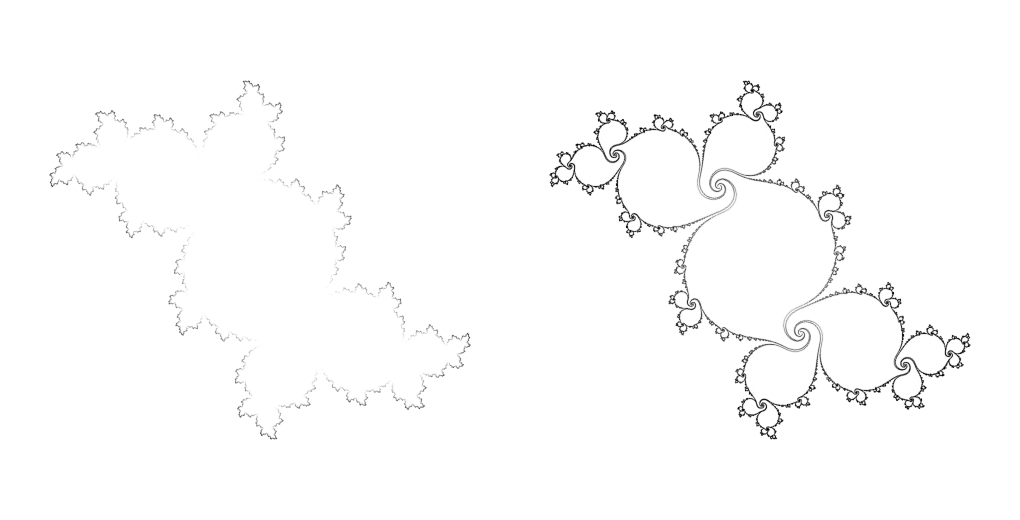

In [20]:
c = -0.11 + 0.65569999 * 1j  # 用另一个 c 来画
r_iim = numba_julia_set_count(c, 1000000)
r_miim = numba_julia_set_count_miim(c, 1000000)

fig, axes = plt.subplots(1, 2, figsize=(10, 6))
fig.subplots_adjust(0, 0, 1, 1, 0, 0)
axes[0].imshow(np.log10(r_iim + 1), cmap="gray_r")
axes[1].imshow(r_miim, cmap="gray_r")
for ax in axes:
    ax.set_aspect("equal")
    ax.axis("off")

## 执行时间的比较

下面是在这个环境(Python 3.14、MinGW-w64 的 gcc、Core i7)里计算 10 万个点的 Julia 集合所用的时间，带小数的值每次都会变，只当作参考看。

| 方法 | 一次的时间 | 与 Python 之比 |
|------|-----------|--------------|
| `py_julia_set()`(Python) | 约 76 ms | 1 |
| `cffi_julia_set()`(CFFI + C) | 约 6.7 ms | 约 11 倍 |
| `cy_julia_set()`(Cython) | 约 5.8 ms | 约 13 倍 |
| `numba_julia_set()`(Numba) | 约 5.4 ms | 约 14 倍 |

计数版(30 万次、格子 300×300)里，`numba_julia_set_count()` 约 5.2 ms，而原来的 Python 函数(`py_func`)约 209 ms。

用 C 写函数再调用的办法，都能比 Python 快十几倍：CFFI 可以直接使用已有的 C 代码、Cython 用接近 Python 的写法指定类型、Numba 则不改 Python 函数就能编译，按实际的任务挑一个即可。


## 小结

* Python 慢，是因为对象把值包了起来，而且在虚拟机上一条条执行指令。
* C 的函数可以用 CFFI 与 ctypes 调用，数组要放在连续的内存里、以指针传递。
* Cython 把类似 Python 的代码转换成 C，用 `cdef` 指定类型之后循环就快了。
* Numba 不用 C 编译器就能编译 Python 函数，但第一次调用要花时间。
* 改变迭代的方式，即使计算量相同，也能把细节求出来。